In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install -q xgboost

In [3]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from xgboost import XGBClassifier

print("Libraries imported successfully")

Libraries imported successfully


In [4]:
diagnostic_path = "/content/drive/MyDrive/AutoSenseAI/data/ML Car Diagnostic Agent AI Assistant.csv"

df = pd.read_csv(diagnostic_path)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (10000, 12)


,Record ID,Car Name,Problem Classification,Problem Description,Severity,Diagnosis,How to Fix the Problem,Solution Used,ECU Data,Service History,Repair Status,Results
0,1,Honda Civic 2019,Electrical,Headlights flicker,Medium,Loose wiring,Check and repair loose or damaged wiring conne...,Check and repair wiring,NaN,Spark plugs replaced 2 years ago,Fixed,Resolved
1,2,Toyota Corolla 2018,Electrical,Power window failure,Medium,Window regulator motor,Check and repair loose or damaged wiring conne...,Check and repair wiring,Multiple codes,Spark plugs replaced 2 years ago,Fixed,Resolved
2,3,BMW i4 2019,Engine,Engine misfire,High,Timing belt failure,Replace spark plugs,Replaced failure,P0101,Regular maintenance,Fixed,Resolved
3,4,Nissan Rogue 2020,Transmission,Transmission overheating,High,Transmission fluid thick,Perform transmission service and inspect for i...,Perform transmission service,NaN,Spark plugs replaced 2 years ago,Fixed,Resolved
4,5,Mercedes S-Class 2020,Battery,Battery drains fast,High,Dead battery,Replace battery and test charging system,Replaced battery,NaN,Brake service 1 year ago,Fixed,Resolved


In [5]:
print(df.columns.tolist())

['Record ID', 'Car Name', 'Problem Classification', 'Problem Description', 'Severity', 'Diagnosis', 'How to Fix the Problem', 'Solution Used', 'ECU Data', 'Service History', 'Repair Status', 'Results']


In [6]:
print(df.isnull().sum())

Record ID                    0
Car Name                     0
Problem Classification       0
Problem Description          0
Severity                     0
Diagnosis                    0
How to Fix the Problem       0
Solution Used                0
ECU Data                  3320
Service History           1312
Repair Status                0
Results                      0
dtype: int64


In [7]:
df["ECU Data"] = df["ECU Data"].fillna("Unknown")
df["Service History"] = df["Service History"].fillna("Unknown")

In [8]:
print(df[["ECU Data", "Service History"]].isnull().sum())

ECU Data           0
Service History    0
dtype: int64


In [9]:
df["Vehicle_Year"] = pd.to_numeric(
    df["Car Name"].str.extract(r"(\d{4})$")[0],
    errors="coerce"
)

df["Car_Make"] = df["Car Name"].str.split().str[0]

df["Car_Model"] = (
    df["Car Name"]
    .str.replace(r"\s+\d{4}$", "", regex=True)
    .str.split(n=1)
    .str[1]
)

In [10]:
df[
    [
        "Car Name",
        "Car_Make",
        "Car_Model",
        "Vehicle_Year"
    ]
].head()

,Car Name,Car_Make,Car_Model,Vehicle_Year
0,Honda Civic 2019,Honda,Civic,2019
1,Toyota Corolla 2018,Toyota,Corolla,2018
2,BMW i4 2019,BMW,i4,2019
3,Nissan Rogue 2020,Nissan,Rogue,2020
4,Mercedes S-Class 2020,Mercedes,S-Class,2020


In [11]:
target = "Problem Classification"

y = df[target]

print(y.value_counts())

Problem Classification
Electrical      2092
Brakes          2051
Battery         2013
Engine          1959
Transmission    1885
Name: count, dtype: int64


In [12]:
label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

class_mapping = dict(
    zip(
        label_encoder.classes_,
        label_encoder.transform(label_encoder.classes_)
    )
)

print("Class mapping:")
print(class_mapping)

Class mapping:
{'Battery': np.int64(0), 'Brakes': np.int64(1), 'Electrical': np.int64(2), 'Engine': np.int64(3), 'Transmission': np.int64(4)}


In [13]:
basic_features = [
    "Car_Make",
    "Car_Model",
    "Vehicle_Year",
    "Problem Description",
    "Severity"
]

X_basic = df[basic_features]

print(X_basic.head())
print("Basic feature shape:", X_basic.shape)

   Car_Make Car_Model  Vehicle_Year       Problem Description Severity
0     Honda     Civic          2019        Headlights flicker   Medium
1    Toyota   Corolla          2018      Power window failure   Medium
2       BMW        i4          2019            Engine misfire     High
3    Nissan     Rogue          2020  Transmission overheating     High
4  Mercedes   S-Class          2020       Battery drains fast     High
Basic feature shape: (10000, 5)


In [14]:
X_basic_train, X_basic_test, y_basic_train, y_basic_test = train_test_split(
    X_basic,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Basic train:", X_basic_train.shape)
print("Basic test:", X_basic_test.shape)

Basic train: (8000, 5)
Basic test: (2000, 5)


In [15]:
basic_categorical = [
    "Car_Make",
    "Car_Model",
    "Problem Description",
    "Severity"
]

basic_numerical = [
    "Vehicle_Year"
]

In [16]:
basic_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            basic_categorical
        ),
        (
            "numerical",
            "passthrough",
            basic_numerical
        )
    ]
)

In [17]:
basic_xgb = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=len(label_encoder.classes_),
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

In [18]:
basic_pipeline = Pipeline(
    steps=[
        ("preprocessor", basic_preprocessor),
        ("classifier", basic_xgb)
    ]
)

In [19]:
basic_pipeline.fit(
    X_basic_train,
    y_basic_train
)

print("Basic model trained successfully")

Basic model trained successfully


In [20]:
basic_pred = basic_pipeline.predict(
    X_basic_test
)

In [21]:
basic_accuracy = accuracy_score(
    y_basic_test,
    basic_pred
)

basic_precision = precision_score(
    y_basic_test,
    basic_pred,
    average="macro"
)

basic_recall = recall_score(
    y_basic_test,
    basic_pred,
    average="macro"
)

basic_f1 = f1_score(
    y_basic_test,
    basic_pred,
    average="macro"
)

print("BASIC MODEL")
print("Accuracy        :", round(basic_accuracy, 4))
print("Macro Precision :", round(basic_precision, 4))
print("Macro Recall    :", round(basic_recall, 4))
print("Macro F1        :", round(basic_f1, 4))

BASIC MODEL
Accuracy        : 0.9325
Macro Precision : 0.9352
Macro Recall    : 0.9339
Macro F1        : 0.934


In [22]:
print(
    classification_report(
        y_basic_test,
        basic_pred,
        target_names=label_encoder.classes_
    )
)

              precision    recall  f1-score   support

     Battery       0.86      0.79      0.83       403
      Brakes       1.00      1.00      1.00       410
  Electrical       0.81      0.88      0.84       418
      Engine       1.00      1.00      1.00       392
Transmission       1.00      1.00      1.00       377

    accuracy                           0.93      2000
   macro avg       0.94      0.93      0.93      2000
weighted avg       0.93      0.93      0.93      2000



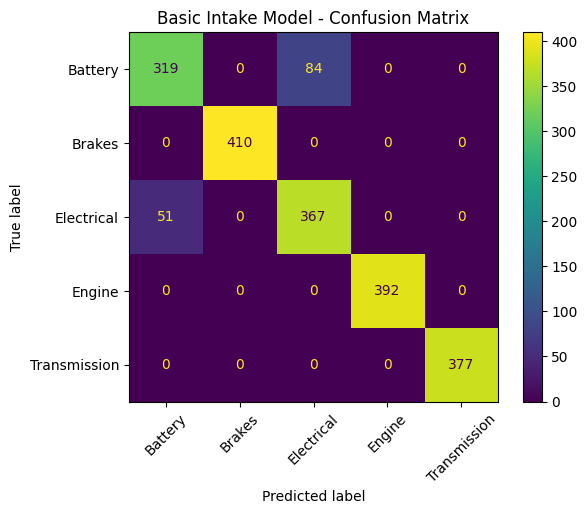

In [23]:
ConfusionMatrixDisplay.from_predictions(
    y_basic_test,
    basic_pred,
    display_labels=label_encoder.classes_,
    xticks_rotation=45
)

plt.title("Basic Intake Model - Confusion Matrix")
plt.show()

In [24]:
enriched_features = [
    "Car_Make",
    "Car_Model",
    "Vehicle_Year",
    "Problem Description",
    "Severity",
    "Service History",
    "ECU Data",
    "Diagnosis"
]

X_enriched = df[enriched_features]

print(X_enriched.head())
print("Enriched feature shape:", X_enriched.shape)

   Car_Make Car_Model  Vehicle_Year       Problem Description Severity  \
0     Honda     Civic          2019        Headlights flicker   Medium   
1    Toyota   Corolla          2018      Power window failure   Medium   
2       BMW        i4          2019            Engine misfire     High   
3    Nissan     Rogue          2020  Transmission overheating     High   
4  Mercedes   S-Class          2020       Battery drains fast     High   

                    Service History        ECU Data                 Diagnosis  
0  Spark plugs replaced 2 years ago         Unknown              Loose wiring  
1  Spark plugs replaced 2 years ago  Multiple codes    Window regulator motor  
2               Regular maintenance           P0101       Timing belt failure  
3  Spark plugs replaced 2 years ago         Unknown  Transmission fluid thick  
4          Brake service 1 year ago         Unknown              Dead battery  
Enriched feature shape: (10000, 8)


In [25]:
X_enriched_train, X_enriched_test, y_enriched_train, y_enriched_test = train_test_split(
    X_enriched,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

In [26]:
enriched_categorical = [
    "Car_Make",
    "Car_Model",
    "Problem Description",
    "Severity",
    "Service History",
    "ECU Data",
    "Diagnosis"
]

enriched_numerical = [
    "Vehicle_Year"
]

In [27]:
enriched_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            enriched_categorical
        ),
        (
            "numerical",
            "passthrough",
            enriched_numerical
        )
    ]
)

In [28]:
enriched_xgb = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=len(label_encoder.classes_),
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

In [29]:
enriched_pipeline = Pipeline(
    steps=[
        ("preprocessor", enriched_preprocessor),
        ("classifier", enriched_xgb)
    ]
)

In [30]:
enriched_pipeline.fit(
    X_enriched_train,
    y_enriched_train
)

print("Enriched model trained successfully")

Enriched model trained successfully


In [31]:
enriched_pred = enriched_pipeline.predict(
    X_enriched_test
)

In [32]:
enriched_accuracy = accuracy_score(
    y_enriched_test,
    enriched_pred
)

enriched_precision = precision_score(
    y_enriched_test,
    enriched_pred,
    average="macro"
)

enriched_recall = recall_score(
    y_enriched_test,
    enriched_pred,
    average="macro"
)

enriched_f1 = f1_score(
    y_enriched_test,
    enriched_pred,
    average="macro"
)

print("ENRICHED MODEL")
print("Accuracy        :", round(enriched_accuracy, 4))
print("Macro Precision :", round(enriched_precision, 4))
print("Macro Recall    :", round(enriched_recall, 4))
print("Macro F1        :", round(enriched_f1, 4))

ENRICHED MODEL
Accuracy        : 0.974
Macro Precision : 0.9749
Macro Recall    : 0.9745
Macro F1        : 0.9746


In [33]:
print(
    classification_report(
        y_enriched_test,
        enriched_pred,
        target_names=label_encoder.classes_
    )
)

              precision    recall  f1-score   support

     Battery       0.95      0.92      0.93       403
      Brakes       1.00      1.00      1.00       410
  Electrical       0.93      0.95      0.94       418
      Engine       1.00      1.00      1.00       392
Transmission       1.00      1.00      1.00       377

    accuracy                           0.97      2000
   macro avg       0.97      0.97      0.97      2000
weighted avg       0.97      0.97      0.97      2000



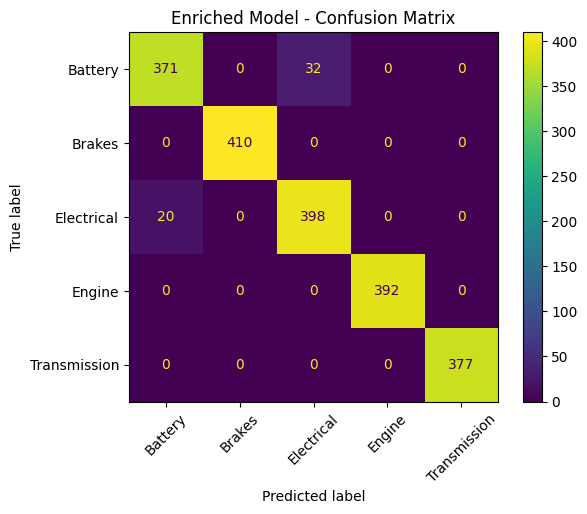

In [34]:
ConfusionMatrixDisplay.from_predictions(
    y_enriched_test,
    enriched_pred,
    display_labels=label_encoder.classes_,
    xticks_rotation=45
)

plt.title("Enriched Model - Confusion Matrix")
plt.show()

In [35]:
comparison_df = pd.DataFrame({
    "Model": [
        "Basic",
        "Enriched"
    ],

    "Accuracy": [
        basic_accuracy,
        enriched_accuracy
    ],

    "Macro Precision": [
        basic_precision,
        enriched_precision
    ],

    "Macro Recall": [
        basic_recall,
        enriched_recall
    ],

    "Macro F1": [
        basic_f1,
        enriched_f1
    ]
})

comparison_df

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Basic,0.9325,0.935182,0.933911,0.934001
1,Enriched,0.9740,0.974886,0.974550,0.974638


In [36]:
comparison_percent = comparison_df.copy()

for col in [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1"
]:
    comparison_percent[col] = (
        comparison_percent[col] * 100
    ).round(2)

comparison_percent

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Basic,93.25,93.52,93.39,93.40
1,Enriched,97.40,97.49,97.45,97.46


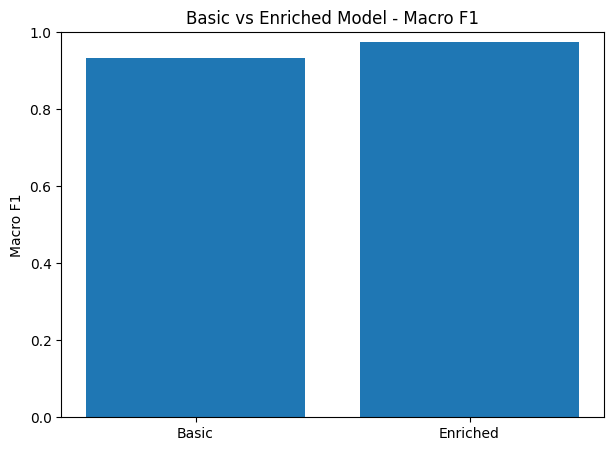

In [37]:
plt.figure(figsize=(7, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Macro F1"]
)

plt.title(
    "Basic vs Enriched Model - Macro F1"
)

plt.ylabel(
    "Macro F1"
)

plt.ylim(0, 1)

plt.show()

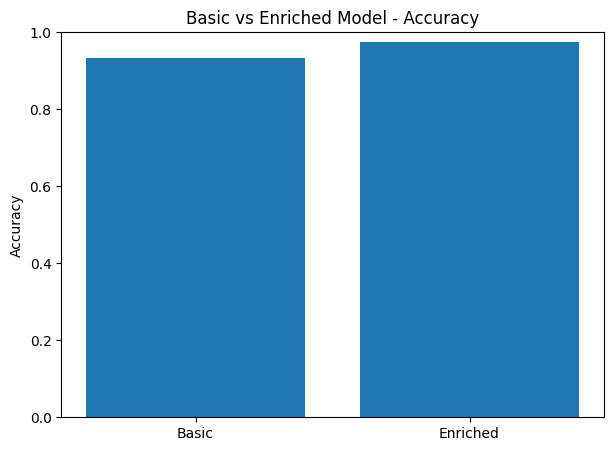

In [38]:
plt.figure(figsize=(7, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Accuracy"]
)

plt.title(
    "Basic vs Enriched Model - Accuracy"
)

plt.ylabel(
    "Accuracy"
)

plt.ylim(0, 1)

plt.show()

In [39]:
accuracy_improvement = (
    enriched_accuracy - basic_accuracy
)

f1_improvement = (
    enriched_f1 - basic_f1
)

print(
    "Accuracy improvement:",
    round(accuracy_improvement * 100, 2),
    "percentage points"
)

print(
    "Macro F1 improvement:",
    round(f1_improvement * 100, 2),
    "percentage points"
)

Accuracy improvement: 4.15 percentage points
Macro F1 improvement: 4.06 percentage points


In [40]:
results_dir = "/content/drive/MyDrive/AutoSenseAI/results"

os.makedirs(
    results_dir,
    exist_ok=True
)

print("Results folder ready")

Results folder ready


In [41]:
comparison_df.to_csv(
    os.path.join(
        results_dir,
        "basic_vs_enriched_comparison.csv"
    ),
    index=False
)

print("Comparison saved")

Comparison saved


In [42]:
model_dir = "/content/drive/MyDrive/AutoSenseAI/models"

os.makedirs(
    model_dir,
    exist_ok=True
)

In [43]:
basic_model_path = os.path.join(
    model_dir,
    "maintenance_category_basic_xgboost.pkl"
)

joblib.dump(
    basic_pipeline,
    basic_model_path
)

print(
    "Basic model saved:",
    basic_model_path
)

Basic model saved: /content/drive/MyDrive/AutoSenseAI/models/maintenance_category_basic_xgboost.pkl


In [44]:
basic_encoder_path = os.path.join(
    model_dir,
    "maintenance_category_basic_encoder.pkl"
)

joblib.dump(
    label_encoder,
    basic_encoder_path
)

print(
    "Basic encoder saved:",
    basic_encoder_path
)

Basic encoder saved: /content/drive/MyDrive/AutoSenseAI/models/maintenance_category_basic_encoder.pkl


In [45]:
enriched_model_path = os.path.join(
    model_dir,
    "maintenance_category_enriched_xgboost.pkl"
)

joblib.dump(
    enriched_pipeline,
    enriched_model_path
)

print(
    "Enriched model saved:",
    enriched_model_path
)

Enriched model saved: /content/drive/MyDrive/AutoSenseAI/models/maintenance_category_enriched_xgboost.pkl


In [46]:
enriched_encoder_path = os.path.join(
    model_dir,
    "maintenance_category_enriched_encoder.pkl"
)

joblib.dump(
    label_encoder,
    enriched_encoder_path
)

print(
    "Enriched encoder saved:",
    enriched_encoder_path
)

Enriched encoder saved: /content/drive/MyDrive/AutoSenseAI/models/maintenance_category_enriched_encoder.pkl


In [47]:
print("\nSaved model files:")

for file in os.listdir(model_dir):
    if "maintenance_category" in file:
        print(file)


Saved model files:
maintenance_category_xgboost.pkl
maintenance_category_label_encoder.pkl
maintenance_category_basic_xgboost.pkl
maintenance_category_basic_encoder.pkl
maintenance_category_enriched_xgboost.pkl
maintenance_category_enriched_encoder.pkl


In [48]:
basic_test_vehicle = pd.DataFrame([
    {
        "Car_Make": "Toyota",
        "Car_Model": "Corolla",
        "Vehicle_Year": 2018,
        "Problem Description": "Brake noise",
        "Severity": "High"
    }
])

In [49]:
basic_prediction = basic_pipeline.predict(
    basic_test_vehicle
)

basic_probabilities = basic_pipeline.predict_proba(
    basic_test_vehicle
)

basic_category = label_encoder.inverse_transform(
    basic_prediction
)[0]

basic_confidence = basic_probabilities.max()

print(
    "Basic predicted category:",
    basic_category
)

print(
    "Basic model score:",
    round(
        basic_confidence,
        4
    )
)

Basic predicted category: Brakes
Basic model score: 0.999


In [50]:
enriched_test_vehicle = pd.DataFrame([
    {
        "Car_Make": "Toyota",
        "Car_Model": "Corolla",
        "Vehicle_Year": 2018,
        "Problem Description": "Brake noise",
        "Severity": "High",
        "Service History": "Brake service completed last year",
        "ECU Data": "Unknown",
        "Diagnosis": "Brake pad wear"
    }
])

In [51]:
enriched_prediction = enriched_pipeline.predict(
    enriched_test_vehicle
)

enriched_probabilities = enriched_pipeline.predict_proba(
    enriched_test_vehicle
)

enriched_category = label_encoder.inverse_transform(
    enriched_prediction
)[0]

enriched_confidence = enriched_probabilities.max()

print(
    "Enriched predicted category:",
    enriched_category
)

print(
    "Enriched model score:",
    round(
        enriched_confidence,
        4
    )
)

Enriched predicted category: Brakes
Enriched model score: 0.9662


In [52]:
basic_scores = dict(
    zip(
        label_encoder.classes_,
        basic_probabilities[0]
    )
)

print("Basic scores:")

for category, score in basic_scores.items():
    print(
        category,
        ":",
        round(score, 4)
    )

Basic scores:
Battery : 0.0004
Brakes : 0.999
Electrical : 1e-04
Engine : 0.0002
Transmission : 0.0002


In [53]:
enriched_scores = dict(
    zip(
        label_encoder.classes_,
        enriched_probabilities[0]
    )
)

print("\nEnriched scores:")

for category, score in enriched_scores.items():
    print(
        category,
        ":",
        round(score, 4)
    )


Enriched scores:
Battery : 0.0142
Brakes : 0.9662
Electrical : 0.003
Engine : 0.0085
Transmission : 0.0081


In [54]:
sample_index = 0

print(
    df.loc[
        sample_index,
        enriched_features + [target]
    ]
)

Car_Make                                             Honda
Car_Model                                            Civic
Vehicle_Year                                          2019
Problem Description                     Headlights flicker
Severity                                            Medium
Service History           Spark plugs replaced 2 years ago
ECU Data                                           Unknown
Diagnosis                                     Loose wiring
Problem Classification                          Electrical
Name: 0, dtype: object


In [55]:
sample_input = df.loc[
    [sample_index],
    enriched_features
]

actual_label = df.loc[
    sample_index,
    target
]

prediction = enriched_pipeline.predict(
    sample_input
)

predicted_label = label_encoder.inverse_transform(
    prediction
)[0]

print("Actual:", actual_label)
print("Predicted:", predicted_label)

Actual: Electrical
Predicted: Electrical


Experiment: Multi-Source Information Enrichment

Objective:
To evaluate whether combining service-center diagnostic information
with customer/basic vehicle information improves maintenance-category
prediction.

Model A:
Basic intake model using vehicle and customer-provided information.

Model B:
Enriched model using vehicle/customer information plus service history,
ECU data and technician diagnosis.

Evaluation:
Accuracy, Macro Precision, Macro Recall and Macro F1.

Result:
[Insert actual results after model evaluation.]

Interpretation:
If the enriched model produces better Macro F1, the results support the
panel recommendation that maintenance prediction should not rely solely
on information provided by customers.